# Praktikum 4 Data Mining - Sequential Pattern Mining

|Nama|NRP|
|-|-|
|Vincent Valentino|5054251016|

## Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from mlxtend.preprocessing import TransactionEncoder
from prefixspan import PrefixSpan

## Data Exploration

In [2]:
retail = pd.read_excel('Online Retail.xlsx')
display(retail.shape)
display(retail.head())

(541909, 8)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
retail.describe(include='all')

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
count,541909.0,541909,540455,541909.000000,541909,541909.000000,406829.000000,541909
unique,25900.0,4070,4223,NaN,NaN,NaN,NaN,38
top,573585.0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom
freq,1114.0,2313,2369,NaN,NaN,NaN,NaN,495478
mean,NaN,NaN,NaN,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000,NaN
25%,NaN,NaN,NaN,1.000000,2011-03-28 11:34:00,1.250000,13953.000000,NaN
50%,NaN,NaN,NaN,3.000000,2011-07-19 17:17:00,2.080000,15152.000000,NaN
75%,NaN,NaN,NaN,10.000000,2011-10-19 11:27:00,4.130000,16791.000000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN


In [4]:
retail.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [5]:
print(retail.duplicated().sum())
retail.isna().sum()

5268


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

## Pre-processing

In [6]:
raw_rows = len(retail)
raw_invoices = retail['InvoiceNo'].nunique()
raw_customers = retail['CustomerID'].nunique()

In [7]:
cleaned = retail.dropna(subset='Description').copy()
cleaned = cleaned.drop_duplicates()
cleaned['Description'] = cleaned['Description'].astype(str).str.strip()

In [8]:
cleaned = cleaned[~cleaned['InvoiceNo'].astype(str).str.startswith('C')]

In [9]:
cleaned = cleaned[cleaned['Quantity'] > 0]

In [10]:
cleaned = cleaned.dropna(subset=['CustomerID'])
cleaned['CustomerID'] = cleaned['CustomerID'].astype(int)


In [11]:
rows_after = len(cleaned)
invoices_after = cleaned['InvoiceNo'].nunique()

print('Setelah Cleaning')
print(f'Jumlah baris   : {rows_after}')
print(f'Jumlah invoice : {invoices_after}')

Setelah Cleaning
Jumlah baris   : 392732
Jumlah invoice : 18536


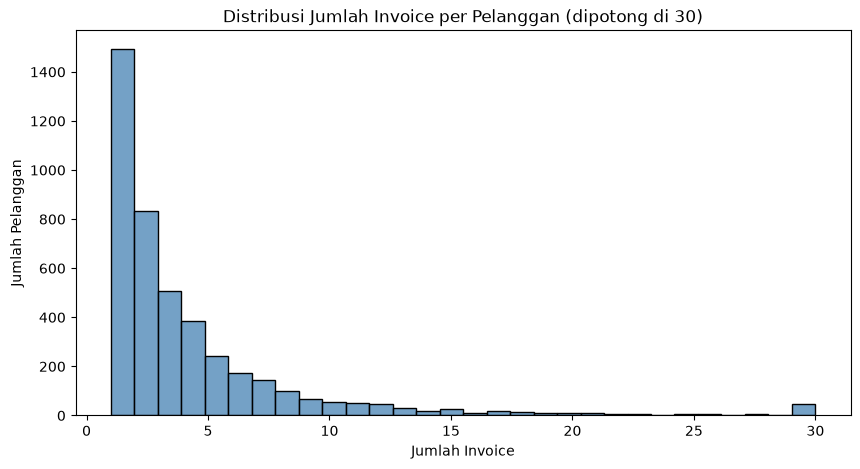

Pelanggan dengan 1 invoice saja : 1494 (34.43189675040332%)
Median invoice per pelanggan    : 2.0


In [19]:
inv_per_cust = cleaned.groupby('CustomerID')['InvoiceNo'].nunique()

plt.figure(figsize=(10, 5))
sb.histplot(inv_per_cust.clip(upper=30), bins=30, color='steelblue')
plt.title('Distribusi Jumlah Invoice per Pelanggan (dipotong di 30)')
plt.xlabel('Jumlah Invoice')
plt.ylabel('Jumlah Pelanggan')
plt.savefig('invoice_per_customer.png', dpi=150)
plt.show()

print(f"Pelanggan dengan 1 invoice saja : {(inv_per_cust == 1).sum()} ({(inv_per_cust == 1).mean()*100}%)")
print(f"Median invoice per pelanggan    : {inv_per_cust.median()}")

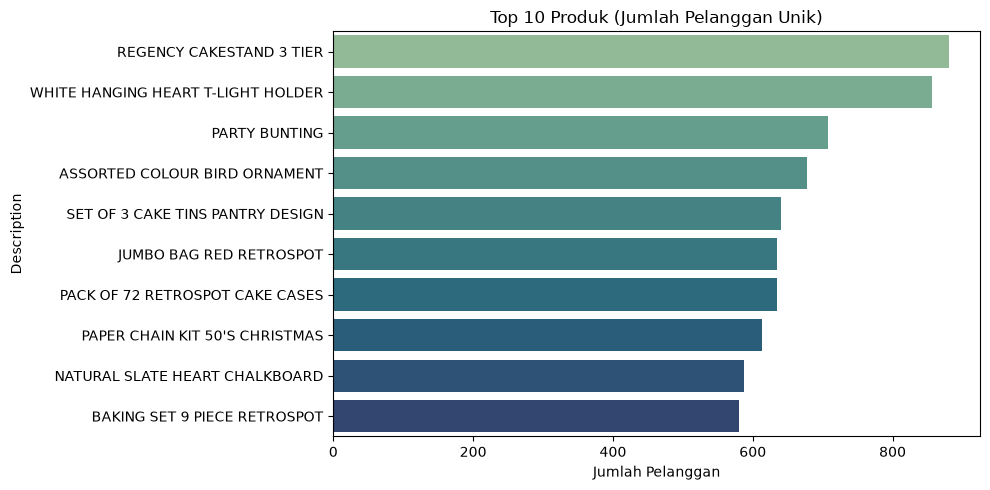

In [20]:
top_items = cleaned.groupby('Description')['CustomerID'].nunique().nlargest(10).reset_index()

plt.figure(figsize=(10, 5))
sb.barplot(data=top_items, y='Description', x='CustomerID', hue='Description', palette='crest', legend=False)
plt.title('Top 10 Produk (Jumlah Pelanggan Unik)')
plt.xlabel('Jumlah Pelanggan')
plt.tight_layout()
plt.savefig('top_items.png', dpi=150)
plt.show()

## Sequential Pattern Mining

In [12]:
cleaned['InvoiceDate'] = pd.to_datetime(cleaned['InvoiceDate'])
top_100_items = set(cleaned.groupby('Description')['CustomerID'].nunique().nlargest(100).index)
df_filtered = cleaned[cleaned['Description'].isin(top_100_items)].sort_values(by=['CustomerID', 'InvoiceDate'])

In [13]:
invoice_grouped = (df_filtered.groupby(['CustomerID', 'InvoiceNo', 'InvoiceDate'])['Description'].apply(lambda items: sorted(list(set(items)))).reset_index().sort_values(by=['CustomerID', 'InvoiceDate']))

In [14]:
customer_sequences = (invoice_grouped.groupby('CustomerID')['Description'].apply(lambda baskets: [item for basket in baskets for item in basket]).tolist())
print(f"Total Sequence Pelanggan: {len(customer_sequences)}")

Total Sequence Pelanggan: 3974


In [15]:
total_customers = len(customer_sequences)
min_sup_ratio = 0.01
min_sup_count = int(min_sup_ratio * total_customers)

print(f"Total Pelanggan Terproses: {total_customers}")
print(f"Minimum Support Threshold: {min_sup_count} pelanggan")

ps = PrefixSpan(customer_sequences)
ps.minlen = 1
ps.maxlen = 2

discovered_patterns = ps.frequent(min_sup_count)
print(f"Total pola berurutan frekuen yang ditemukan: {len(discovered_patterns)}")

Total Pelanggan Terproses: 3974
Minimum Support Threshold: 39 pelanggan
Total pola berurutan frekuen yang ditemukan: 7914


In [16]:
single_item_counts = {pat[0]: count for count, pat in discovered_patterns if len(pat) == 1}

sequential_rules = []
for count, pat in discovered_patterns:
    if len(pat) == 2:
        antecedent = pat[0]
        consequent = pat[1]
        ant_count = single_item_counts.get(antecedent, count)
        
        support_ratio = count / total_customers
        confidence = count / ant_count if ant_count > 0 else 0.0
        
        sequential_rules.append({
            'Antecedent': antecedent,
            'Consequent': consequent,
            'Support Count': count,
            'Support (%)': round(support_ratio * 100, 2),
            'Confidence (%)': round(confidence * 100, 2)
        })

rules_df = pd.DataFrame(sequential_rules).sort_values(
    by=['Support Count', 'Confidence (%)'], ascending=[False, False]
)

print("TOP 10 POLA BERURUTAN TERBAIK BERDASARKAN SUPPORT:")
print(rules_df.head(10).to_string(index=False))

TOP 10 POLA BERURUTAN TERBAIK BERDASARKAN SUPPORT:
                        Antecedent                         Consequent  Support Count  Support (%)  Confidence (%)
WHITE HANGING HEART T-LIGHT HOLDER WHITE HANGING HEART T-LIGHT HOLDER            405        10.19           47.31
          REGENCY CAKESTAND 3 TIER           REGENCY CAKESTAND 3 TIER            330         8.30           37.46
    PAPER CHAIN KIT 50'S CHRISTMAS  PAPER CHAIN KIT VINTAGE CHRISTMAS            321         8.08           52.37
   GREEN REGENCY TEACUP AND SAUCER    ROSES REGENCY TEACUP AND SAUCER            318         8.00           82.17
           JUMBO BAG RED RETROSPOT            JUMBO BAG RED RETROSPOT            312         7.85           49.13
          REGENCY CAKESTAND 3 TIER    ROSES REGENCY TEACUP AND SAUCER            299         7.52           33.94
  RED HANGING HEART T-LIGHT HOLDER WHITE HANGING HEART T-LIGHT HOLDER            293         7.37           76.10
               LUNCH BAG CARS BLUE   

## Pola Berurutan dengan Produk Berbeda (Antecedent ≠ Consequent)

In [17]:
distinct_df = rules_df[rules_df['Antecedent'] != rules_df['Consequent']]

print("TOP 10 POLA BERURUTAN (PRODUK BERBEDA):")
print(distinct_df.head(10).to_string(index=False))

TOP 10 POLA BERURUTAN (PRODUK BERBEDA):
                      Antecedent                         Consequent  Support Count  Support (%)  Confidence (%)
  PAPER CHAIN KIT 50'S CHRISTMAS  PAPER CHAIN KIT VINTAGE CHRISTMAS            321         8.08           52.37
 GREEN REGENCY TEACUP AND SAUCER    ROSES REGENCY TEACUP AND SAUCER            318         8.00           82.17
        REGENCY CAKESTAND 3 TIER    ROSES REGENCY TEACUP AND SAUCER            299         7.52           33.94
RED HANGING HEART T-LIGHT HOLDER WHITE HANGING HEART T-LIGHT HOLDER            293         7.37           76.10
             LUNCH BAG CARS BLUE            LUNCH BAG RED RETROSPOT            293         7.37           61.17
           HEART OF WICKER LARGE              HEART OF WICKER SMALL            292         7.35           60.21
        REGENCY CAKESTAND 3 TIER         SET OF 3 REGENCY CAKE TINS            290         7.30           32.92
                   PARTY BUNTING                     SPOTTY BUNT

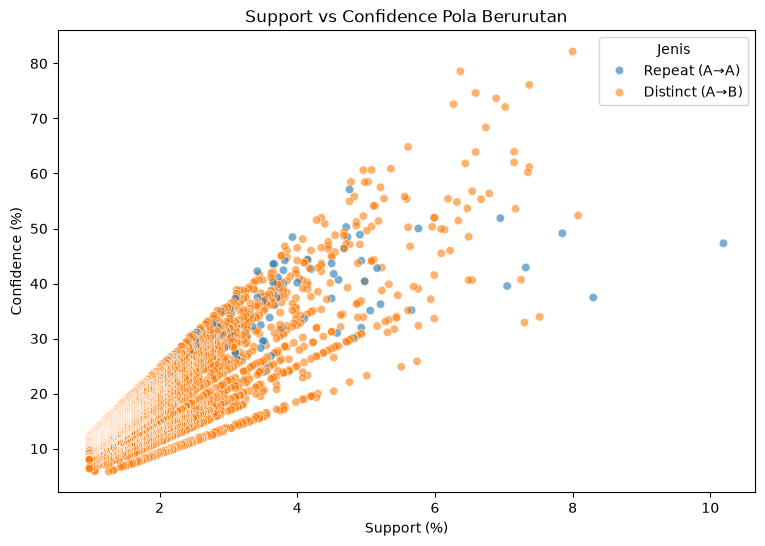

In [22]:
plot_df = rules_df.copy()
plot_df['Jenis'] = np.where(plot_df['Antecedent'] == plot_df['Consequent'], 'Repeat (A→A)', 'Distinct (A→B)')

plt.figure(figsize=(9, 6))
sb.scatterplot(data=plot_df, x='Support (%)', y='Confidence (%)', hue='Jenis', alpha=0.6)
plt.title('Support vs Confidence Pola Berurutan')
plt.savefig('support_confidence.png', dpi=150)
plt.show()

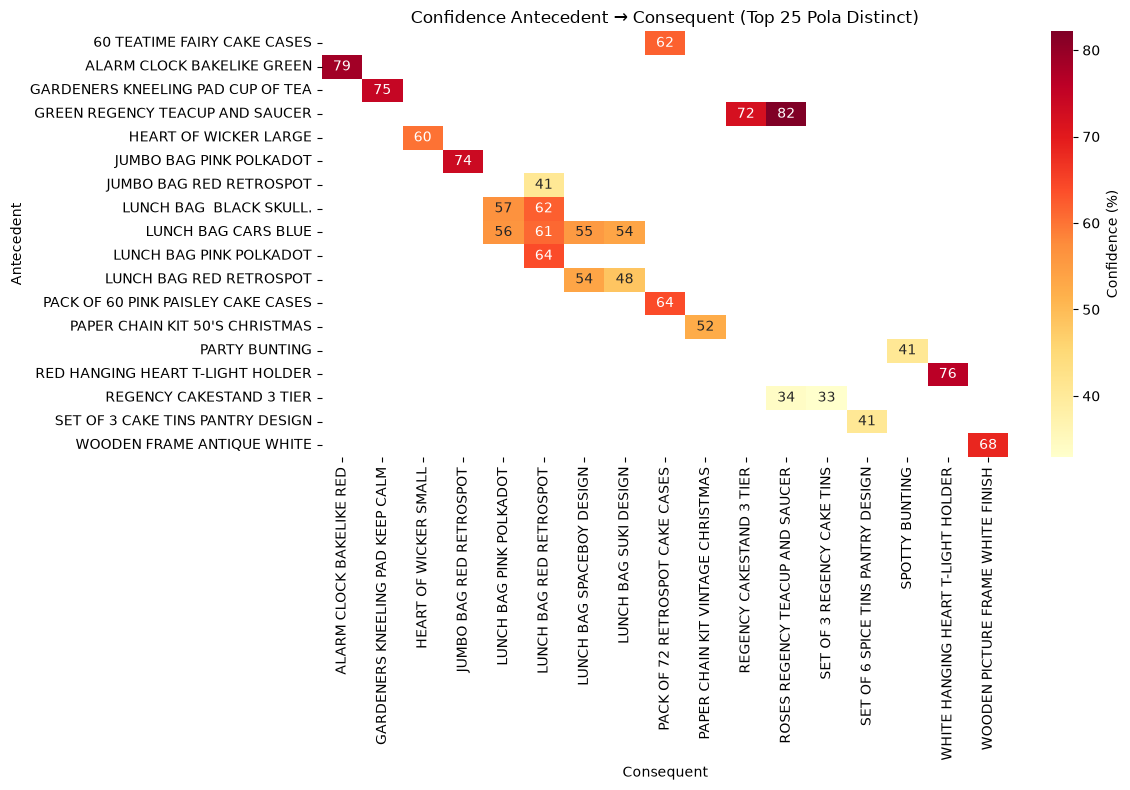

In [23]:
top_d = distinct_df.head(25)
pivot = top_d.pivot_table(index='Antecedent', columns='Consequent', values='Confidence (%)')

plt.figure(figsize=(12, 8))
sb.heatmap(pivot, annot=True, fmt='.0f', cmap='YlOrRd', cbar_kws={'label': 'Confidence (%)'})
plt.title('Confidence Antecedent → Consequent (Top 25 Pola Distinct)')
plt.tight_layout()
plt.savefig('heatmap_confidence.png', dpi=150)
plt.show()

Percobaan lain dengan minimum support lainnya.

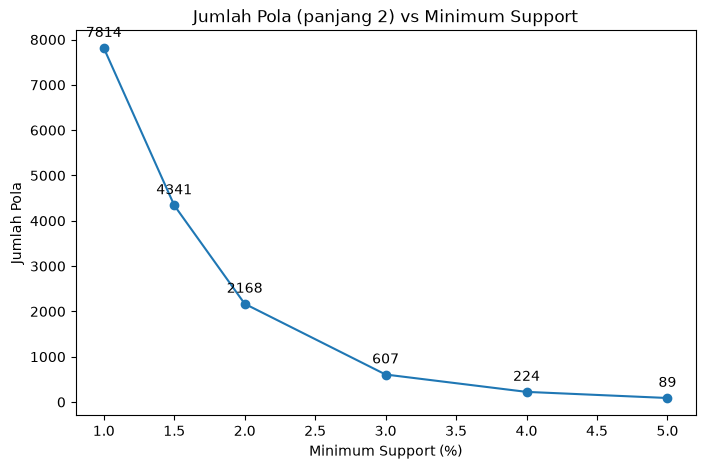

In [21]:
sup_values = [0.01, 0.015, 0.02, 0.03, 0.04, 0.05]
n_patterns = []
for s in sup_values:
    p = PrefixSpan(customer_sequences); p.minlen = 2; p.maxlen = 2
    n_patterns.append(len(p.frequent(int(s * total_customers))))

plt.figure(figsize=(8, 5))
plt.plot([s*100 for s in sup_values], n_patterns, marker='o')
for x, y in zip(sup_values, n_patterns): 
    plt.annotate(y, (x*100, y), textcoords='offset points', xytext=(0, 8), ha='center')
plt.title('Jumlah Pola (panjang 2) vs Minimum Support')
plt.xlabel('Minimum Support (%)')
plt.ylabel('Jumlah Pola')
plt.savefig('minsup.png', dpi=150)
plt.show()

## Interpretasi 3 Pola Terbaik (Produk Berbeda)

| # | Antecedent - Consequent | Support | Confidence |
|-|-|-|-|
| 1 | PAPER CHAIN KIT 50'S CHRISTMAS → PAPER CHAIN KIT VINTAGE CHRISTMAS | 321 pelanggan (8,08%) | 52,37% |
| 2 | GREEN REGENCY TEACUP AND SAUCER → ROSES REGENCY TEACUP AND SAUCER | 318 pelanggan (8,00%) | 82,17% |
| 3 | REGENCY CAKESTAND 3 TIER → ROSES REGENCY TEACUP AND SAUCER | 299 pelanggan (7,52%) | 33,94% |

### 1. Paper Chain Kit 50's Christmas - Paper Chain Kit Vintage Christmas

Sekitar 8% pelanggan membeli Paper Chain Kit 50's Christmas terlebih dahulu, kemudian kembali untuk membeli varian Vintage Christmas. Bahkan, 52% pembeli varian 50's menunjukkan pola pembelian lanjutan ini. Hal ini mengindikasikan bahwa pelanggan tertarik mengoleksi beberapa motif sekaligus, terutama untuk melengkapi dekorasi menjelang Natal.

**Rekomendasi bisnis:** Penjual dapat menawarkan bundle "Christmas Paper Chain Collection" yang menggabungkan kedua varian. Selain itu, pelanggan yang sudah membeli varian 50's dapat diberikan rekomendasi atau promosi khusus untuk varian Vintage. Ketersediaan stok kedua produk juga perlu diperhatikan menjelang musim Natal, khususnya pada periode Oktober hingga Desember.

### 2. Green Regency Teacup & Saucer - Roses Regency Teacup & Saucer

Pola pembelian ini memiliki confidence tertinggi, yaitu 82%. Artinya, sebagian besar pelanggan yang membeli Green Regency Teacup & Saucer juga cenderung membeli varian Roses Regency pada transaksi berikutnya. Hal ini menunjukkan bahwa pelanggan kemungkinan tertarik melengkapi koleksi produk Regency dengan motif yang berbeda.

**Rekomendasi bisnis:** Penjual dapat memasarkan produk Regency sebagai satu koleksi dengan berbagai pilihan motif yang dapat dipadukan. Fitur rekomendasi seperti "Lengkapi Koleksi Anda" juga dapat ditampilkan pada halaman produk untuk mendorong pembelian varian lainnya.

### 3. Regency Cakestand 3 Tier - Roses Regency Teacup & Saucer

Sekitar 7,5% pelanggan membeli Regency Cakestand 3 Tier terlebih dahulu, kemudian kembali untuk membeli Roses Regency Teacup & Saucer. Pola ini menunjukkan kemungkinan adanya keterkaitan antara kedua produk dalam satu kebutuhan, yaitu perlengkapan penyajian teh atau *afternoon tea*. Setelah membeli cakestand untuk menyajikan kue, pelanggan mungkin tertarik melengkapi perlengkapannya dengan cangkir teh yang memiliki desain senada.

**Rekomendasi bisnis:** Penjual dapat menawarkan paket "Afternoon Tea Set" yang menggabungkan cakestand dan teacup.
